# P2.08 — Mortgage rates and the price cycle

**Questions:** RQ1.7 (how have mortgage rates affected ownership affordability?), RQ9.2 (rates and prices), RQ9.5 (how
did crises and monetary shifts affect affordability and construction?). Complements `p1_01`/`p1_02`, which show that the
rate drives the *burden* of buying; here the question is whether it also moves the *price*.

National quarterly series, 2003 to 2026: real and nominal house price index (BIS, INE's from 2009), the agreed rate on new
housing loans (Banco de Portugal) and the payment it implies. Association in time only: the rate is set for the euro area,
is persistent, and 23 years hold two or three regimes. Total new lending is not available (the loan volume we hold covers
loans fixed for up to a year), so credit supply is not tested (RQ9.3 stays open).

In [1]:
import pandas as pd

from pthousing.analysis import macro, supply
from pthousing.data import interim
from pthousing.viz import charts, dashboard, style

style.apply_style()
frame = macro.quarterly_frame(interim.read("bis_spp"), interim.read("bp_mortgage"))
changes = macro.add_changes(frame)
completions = supply.national_flows(dashboard.load_panel())["completed_n"]
print(
    f"{frame.index.min():%Y-Q}{frame.index.min().quarter} to {frame.index.max():%Y}-Q{frame.index.max().quarter}, {len(frame)} quarters"
)

2003-Q1 to 2026-Q1, 93 quarters


## Step 1 — Episodes
Boundaries come from the data, not from the outcome: the quarter before the 2008 financial crisis broke out (Q3 2008), the
low of the real price index, the low of the rate after it, the rate's peak and the last quarter.

In [2]:
price, rate = frame["hpi_real_b2010"], frame["mortgage_rate_new_lt1y_pct"]
crisis = "2008Q3"
trough = price.loc["2008-07-01":].idxmin()
rate_low = rate.loc[trough:].idxmin()
rate_high = rate.loc[rate_low:].idxmax()
q = lambda t: f"{t.year}Q{t.quarter}"  # noqa: E731
last = q(frame.index[-1])
windows = {
    "before the crisis": ("2003Q1", "2008Q2"),
    "crisis and troika": (crisis, q(trough)),
    "recovery, falling rates": (q(trough), q(rate_low)),
    "rate shock": (q(rate_low), q(rate_high)),
    "since the peak": (q(rate_high), last),
}
epis = macro.episodes(frame, windows, completions)
style.save_table(epis.round(1).reset_index(names="episode"), "p2", "rate_episodes")
epis.round(1)

,start,end,real_price_change_pct,nominal_price_change_pct,rate_start_pct,rate_end_pct,rate_change_pp,payment_change_pct,completions_per_year_n
before the crisis,2003Q1,2008Q2,-12.1,1.6,4.2,5.4,1.2,15.0,73062.5
crisis and troika,2008Q3,2013Q2,-19.4,-13.4,5.7,3.2,-2.5,-25.3,33571.7
"recovery, falling rates",2013Q2,2021Q3,77.9,85.7,3.2,0.6,-2.6,-29.5,11654.2
rate shock,2021Q3,2023Q4,9.0,23.3,0.6,4.8,4.2,72.6,21084.3
since the peak,2023Q4,2026Q1,31.3,37.7,4.8,2.9,-2.0,-21.4,24749.0


## Step 2 — Does a rate change time the price?
Correlation of a year's real price growth with the rate change over the year `k` quarters earlier. With overlapping annual
changes there is about one independent observation a year, so the band is wide.

,0,1,2,3,4,5,6,7,8,9,10,11,12
lag_quarters,-4.00,-3.00,-2.00,-1.00,0.00,1.00,2.00,3.00,4.00,5.00,6.00,7.00,8.00
corr,0.20,0.08,-0.06,-0.20,-0.29,-0.33,-0.32,-0.26,-0.16,-0.04,0.09,0.21,0.32
band,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42,0.42


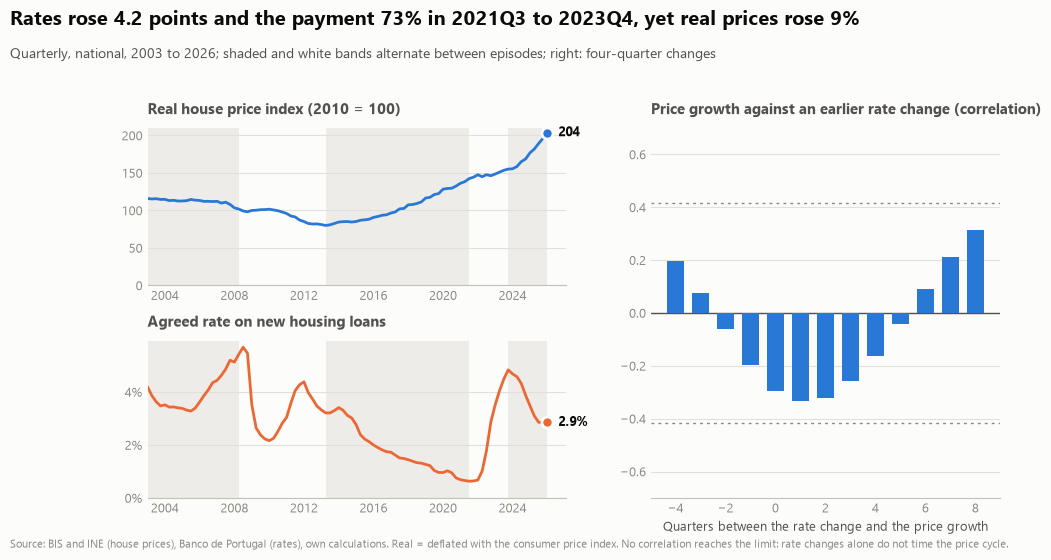

In [3]:
profile = macro.lag_profile(changes, "growth_real_pct", "rate_change_pp", range(-4, 9))
fig = charts.rates_and_cycles(frame, epis, profile)
style.save_fig(fig, "p2", "rates_and_cycles")
style.save_table(profile.round(3), "p2", "rate_lag_profile")
profile.round(2).T

## Step 3 — A pre-specified timing test
Price growth over a year on the rate change over the year before (the lag equals the window, so the two do not overlap; chosen
before looking at the profile), Newey-West standard errors. Add last year's price growth (momentum), a placebo (the rate
change of the year *after*), nominal prices (real prices fall mechanically when inflation jumps), and the two halves of the
sample.

In [4]:
specs = {
    "rate change only": {},
    "+ last year's growth": {"own_lag": True},
    "+ placebo: next year's rate change": {"own_lag": True, "lead": True},
    "nominal prices": {"y": "growth_nominal_pct", "own_lag": True},
    "2003-2013": {"own_lag": True, "sample": ("2003", "2013")},
    "2014-2026": {"own_lag": True, "sample": ("2014", "2026")},
}
timing = pd.DataFrame({k: macro.rate_timing(changes, **v) for k, v in specs.items()}).T
style.save_table(timing.round(3).reset_index(names="specification"), "p2", "rate_timing")
timing.round(3)

,coef_pct_per_pp,ci_low,ci_high,p_value,r2,n,own_lag_coef,lead_coef_pct_per_pp,lead_p_value
rate change only,-0.991,-3.644,1.662,0.464,0.026,85.0,NaN,NaN,NaN
+ last year's growth,-0.020,-1.447,1.407,0.978,0.472,85.0,0.742,NaN,NaN
+ placebo: next year's rate change,0.203,-1.393,1.799,0.803,0.450,81.0,0.677,0.423,0.668
nominal prices,-0.760,-1.921,0.402,0.200,0.591,85.0,0.829,NaN,NaN
2003-2013,-2.031,-3.472,-0.590,0.006,0.221,36.0,-0.259,NaN,NaN
2014-2026,-0.212,-0.722,0.298,0.415,0.122,49.0,0.315,NaN,NaN


## Key numbers

In [5]:
e = epis
shock = e.loc["rate shock"]
print(
    f"rate shock {shock['start']}-{shock['end']}: rate {shock['rate_start_pct']:.1f}% to {shock['rate_end_pct']:.1f}%, "
    f"payment {shock['payment_change_pct']:+.0f}%, real price {shock['real_price_change_pct']:+.0f}% "
    f"(nominal {shock['nominal_price_change_pct']:+.0f}%)"
)
print(
    "crisis: real price",
    f"{e.loc['crisis and troika', 'real_price_change_pct']:+.0f}%, completions per year",
    f"{e.loc['crisis and troika', 'completions_per_year_n']:,.0f} against {e.loc['before the crisis', 'completions_per_year_n']:,.0f} before",
)
for name, row in timing.iterrows():
    print(
        f"{name}: {row['coef_pct_per_pp']:+.2f} points per pp [{row['ci_low']:+.2f}, {row['ci_high']:+.2f}], p={row['p_value']:.2f}, n={int(row['n'])}"
    )

rate shock 2021Q3-2023Q4: rate 0.6% to 4.8%, payment +73%, real price +9% (nominal +23%)
crisis: real price -19%, completions per year 33,572 against 73,062 before
rate change only: -0.99 points per pp [-3.64, +1.66], p=0.46, n=85
+ last year's growth: -0.02 points per pp [-1.45, +1.41], p=0.98, n=85
+ placebo: next year's rate change: +0.20 points per pp [-1.39, +1.80], p=0.80, n=81
nominal prices: -0.76 points per pp [-1.92, +0.40], p=0.20, n=85
2003-2013: -2.03 points per pp [-3.47, -0.59], p=0.01, n=36
2014-2026: -0.21 points per pp [-0.72, +0.30], p=0.42, n=49
